Number of channels: 2
Sample width: 2
Sampling rate: 44100
Number of frames: 286650
Number of sample points: 286650


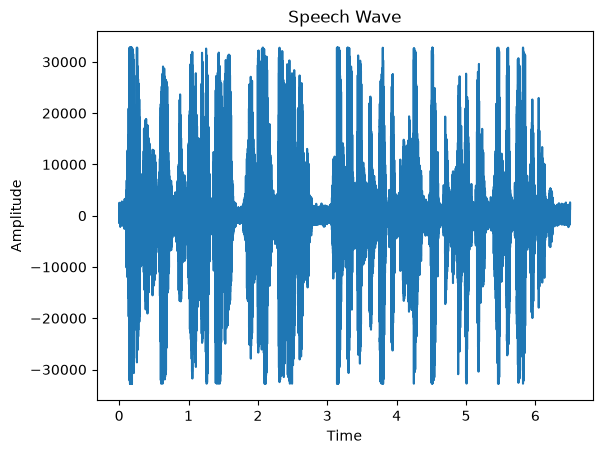

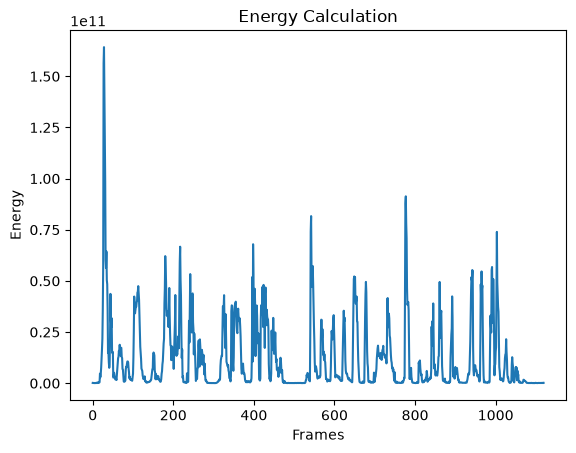

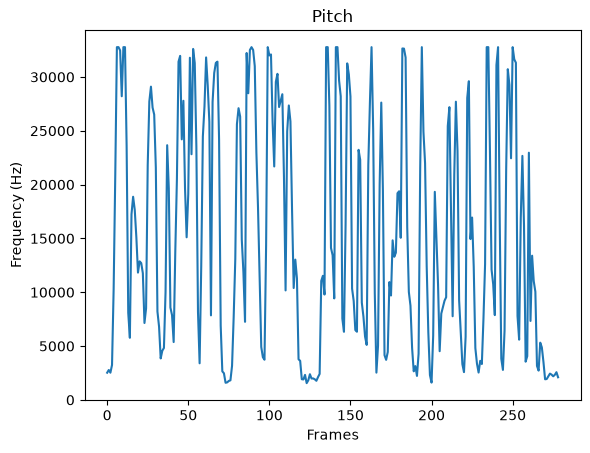

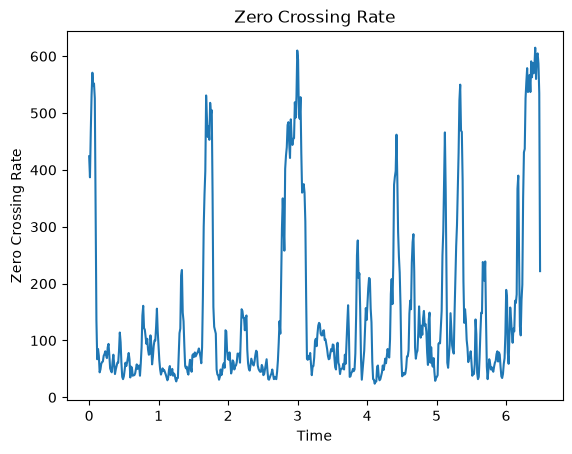

In [2]:
import wave
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read
import math

def calEnergy(x):
    return [sum(x[i:i+256].astype(float)**2) for i in range(0,len(x),256)]

f = wave.open(r"E:\wav files\wav files\speech.wav","rb")
n,s,r,nf = f.getparams()[:4]
print("Number of channels:",n)
print("Sample width:",s)
print("Sampling rate:",r)
print("Number of frames:",nf)

x = np.frombuffer(f.readframes(nf),dtype=np.int16)
if n > 1: x = x.reshape(-1,n).mean(axis=1)
f.close()

print("Number of sample points:",len(x))

plt.figure()
plt.title("Speech Wave")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.plot(np.linspace(0,len(x)/r,len(x)),x)
plt.show()

plt.figure()
plt.plot(calEnergy(x))
plt.axis("tight")
plt.xlabel("Frames")
plt.ylabel("Energy")
plt.title("Energy Calculation")
plt.show()

FRAME_SIZE = 1024

def ProcessFrame(x,Fs):
    return np.max(x)

Fs,d = read(r"E:\wav files\wav files\speech.wav")
if d.ndim > 1: d = d.mean(axis=1)

freq = [ProcessFrame(d[i:i+1024],Fs) for i in range(0,len(d)-1023,1024)]

plt.figure()
plt.plot(freq)
plt.axis("tight")
plt.xlabel("Frames")
plt.ylabel("Frequency (Hz)")
plt.title("Pitch")
plt.show()

def ZeroCR(x,fs,overlap):
    step = fs-overlap
    z = []
    for i in range(0,len(x),step):
        a = x[i:i+fs]
        a = a-np.mean(a)
        z.append(np.sum(a[:-1]*a[1:]<=0))
    return z

z = ZeroCR(d,1024,512)

plt.figure()
plt.plot(np.arange(len(z))*512/Fs,z)
plt.xlabel("Time")
plt.ylabel("Zero Crossing Rate")
plt.title("Zero Crossing Rate")
plt.show()